#### Aula 05 - finalização do Modelo (11/10/2026)

In [ ]:
from datetime import datetime
nome_solucao = "solucao_1"
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

comp_palete = 120
larg_palete = 100 
caixas = [(30, 23, 4), (20, 10, 2)]  #(largura_caixa1, altura_caixa1, qtd_min_caixa1)
qtd_solucoes = 2
tempo_limite = 10

OBJETIVO_QUANTIDADE = "Maximizar quantidade de caixas"
OBJETIVO_AREA_LIVRE = "Minimizar espaço livre no palete"
OBJETIVOS = (OBJETIVO_QUANTIDADE, OBJETIVO_AREA_LIVRE)
objetivo = OBJETIVOS[0]
print(objetivo)


Maximizar quantidade de caixas


In [ ]:
import tempfile
import threading
import subprocess
import os
import time
import pulp as plp
from signal import SIGKILL
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import math

FOLGA_LIMITE_RIGIDO = 10  # segundos extras antes de matar o solver

def _gerar_figura(solucoes: list, L: int, W: int, dims: list, qtd_maxima: int, destacar_area: bool = False):
    """Gera figura matplotlib com as soluções em grade (até 2 por linha).

    ``solucoes`` contém listas de (tipo, orientação, x, y); ``dims`` contém
    (comprimento, largura) de cada tipo de caixa, na ordem dos tipos.
    """
    n = len(solucoes)
    ncols = min(n, 2)
    nrows = math.ceil(n / 2)
    fig, axes = plt.subplots(nrows, ncols, figsize=(10 * ncols, 10 * nrows), squeeze=False)
    fig.set_facecolor("#f4f4f4")

    cmap = plt.get_cmap("tab10")
    cores = {t: cmap((t - 1) % 10) for t in range(1, len(dims) + 1)}

    for idx, (ax, solucao) in enumerate(zip(axes.flat, solucoes), start=1):
        ax.set_facecolor("#f4f4f4")
        ax.set_xlim(-1, L + 1)
        ax.set_ylim(-1, W + 1)
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)

        # Borda da palete
        for x0, y0, x1, y1 in [(0, 0, L, 0), (0, 0, 0, W), (0, W, L, W), (L, 0, L, W)]:
            ax.plot([x0, x1], [y0, y1], "k-", lw=2)

        for n_caixa, (t, o, p, q) in enumerate(solucao, start=1):
            cl, cw = dims[t - 1] if o == 1 else dims[t - 1][::-1]
            ax.add_patch(plt.Rectangle(
                xy=(p, q), width=cl, height=cw,
                facecolor=cores[t], edgecolor="white", lw=1,
                hatch="//" if o == 2 else None,
            ))
            ax.text(
                p + cl / 2, q + cw / 2, f"{n_caixa}\nT{t}",
                ha="center", va="center", fontsize=12, color="#f4f4f4",
            )

        contagem = ", ".join(
            f"T{t}: {sum(1 for c in solucao if c[0] == t)}" for t in range(1, len(dims) + 1)
        )
        area_livre = L * W - sum(
            dims[t - 1][0] * dims[t - 1][1] for t, _, _, _ in solucao
        )
        extra = f" | livre: {area_livre} cm² ({100 * area_livre / (L * W):.1f}%)"
        ax.set_title(
            f"Solução {idx} — {len(solucao)} caixas  (máx. teórico: {qtd_maxima})"
            f"\n(L={L}cm, W={W}cm | {contagem}{extra})",
            fontsize=16,
        )
        ax.tick_params(labelsize=12)

    for ax in list(axes.flat)[n:]:
        ax.set_visible(False)

    legenda = [
        Patch(facecolor=cores[t], label=f"T{t}: {c}×{w} cm")
        for t, (c, w) in enumerate(dims, start=1)
    ] + [Patch(facecolor="white", edgecolor="gray", hatch="//", label="Rotacionada")]
    fig.legend(handles=legenda, loc="lower center", ncol=min(len(legenda), 6), fontsize=14,
               bbox_to_anchor=(0.5, 0))
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    return fig

def _pids_do_solver(diretorio_tmp: str) -> list:
    """PIDs dos processos cuja linha de comando referencia o diretorio temporario."""
    saida = subprocess.run(
        ["pgrep", "-f", diretorio_tmp], capture_output=True, text=True
    ).stdout
    return [int(pid) for pid in saida.split() if int(pid) != os.getpid()]

def resolver_com_limite(problema: plp.LpProblem, solver, tempo_limite: float) -> bool:
    """Resolve ``problema`` e mata o processo do solver se passar do limite.

    O limite nativo do CBC (-sec) nao e checado durante o LP/presolve de modelos
    grandes, entao um watchdog encerra o processo apos ``tempo_limite`` + folga.
    ``solver.tmpDir`` deve ser exclusivo desta chamada: e ele que identifica o
    processo, sem afetar solves concorrentes. Retorna True se o solver terminou
    por conta propria.
    """
    parar = threading.Event()
    estourou = threading.Event()

    def vigiar():
        while not parar.is_set() and not _pids_do_solver(solver.tmpDir):
            parar.wait(0.2)
        # O tempo conta a partir da criacao do processo, nao da escrita do modelo
        if parar.wait(tempo_limite + FOLGA_LIMITE_RIGIDO):
            return
        estourou.set()
        for pid in _pids_do_solver(solver.tmpDir):
            try:
                # os.kill(pid, SIGKILL)
                subprocess.run("kill", "-9", str(pid))
                # pass
            except ProcessLookupError:
                pass

    vigia = threading.Thread(target=vigiar, daemon=True)
    vigia.start()
    try:
        problema.solve(solver)
    except plp.PulpSolverError:
        if not estourou.is_set():
            raise
    finally:
        parar.set()
        vigia.join()
    return not estourou.is_set()

def _somas_atingiveis(dimensoes: list, limite: int) -> list:
    """Coordenadas candidatas: combinações não negativas das dimensões até ``limite``."""
    somas = {0}
    for dimensao in dimensoes:
        somas = {
            soma + qtd * dimensao
            for soma in somas
            for qtd in range((limite - soma) // dimensao + 1)
        }
    return sorted(somas)


def resolver(
    palete_comp: float,
    palete_larg: float,
    caixas: list,
    qtd_solucoes: int = 2,
    tempo_limite: float | None = 60,
    objetivo: str = OBJETIVO_QUANTIDADE,
) -> tuple:
    """
    Resolve o problema de empacotamento via PL inteira (PuLP/CBC).

    Parâmetros
    ----------
    palete_comp, palete_larg : dimensões do palete (cm, arredondadas para int)
    caixas                   : lista de (comprimento, largura, qtd_minima) por tipo
    qtd_solucoes             : quantidade de layouts distintos desejados
    objetivo                 : OBJETIVO_QUANTIDADE (maximiza o nº de caixas) ou
                               OBJETIVO_AREA_LIVRE (minimiza a área não coberta do palete)
    tempo_limite             : segundos por solução (None desliga). Ao estourar, mantém a
                               melhor solução viável já encontrada; sem nenhuma, a busca para

    Retorno
    -------
    (solucoes, qtd_maxima, fig)
      - solucoes   : lista de listas de tuplas (tipo, orientação, x, y); tipo começa em 1
      - qtd_maxima : cota superior teórica (L·W / menor área de caixa)
      - fig        : figura matplotlib com as soluções encontradas
    Retorna (None, qtd_maxima, None) se inviável.
    """
    if not caixas:
        raise ValueError("Informe ao menos um tipo de caixa.")
    if objetivo not in OBJETIVOS:
        raise ValueError(f"objetivo deve ser um de {OBJETIVOS}.")
    if qtd_solucoes < 1:
        raise ValueError("qtd_solucoes deve ser positivo.")
    if tempo_limite is not None and tempo_limite <= 0:
        raise ValueError("tempo_limite deve ser positivo.")

    # Normaliza: L >= W
    L, W = sorted([int(round(palete_comp)), int(round(palete_larg))], reverse=True)
    dims = [(int(round(c)), int(round(w))) for c, w, _ in caixas]
    qtds_minimas = [int(q) for _, _, q in caixas]
    if any(c <= 0 or w <= 0 for c, w in dims):
        raise ValueError("As dimensões das caixas devem ser positivas.")

    qtd_maxima = (L * W) // min(c * w for c, w in dims)

    # Dimensões (comprimento, largura) por tipo e orientação
    orient = {
        (t, o): (dims[t - 1] if o == 1 else dims[t - 1][::-1])
        for t in range(1, len(dims) + 1) for o in (1, 2)
    }

    menor_lado = min(min(d) for d in dims)
    lados = sorted({lado for d in dims for lado in d})
    H = _somas_atingiveis(lados, L - menor_lado)
    V = _somas_atingiveis(lados, W - menor_lado)

    lista_variaveis = [
        (t, o, p, q)
        for (t, o), (cl, cw) in orient.items()
        for p in H if p + cl <= L
        for q in V if q + cw <= W
    ]
    if not lista_variaveis:
        return None, qtd_maxima, None

    # ── Modelo ────────────────────────────────────────────────────────────────
    prob = plp.LpProblem(name="Palete-Caixa", sense=plp.LpMinimize)
    x = plp.LpVariable.dicts(name="C", indices=lista_variaveis, cat=plp.LpBinary)
    if objetivo == OBJETIVO_QUANTIDADE:
        prob += -plp.lpSum(x.values()), "Objetivo"
    else:
        area = lambda c: orient[(c[0], c[1])][0] * orient[(c[0], c[1])][1]
        prob += L * W - plp.lpSum(area(c) * x[c] for c in lista_variaveis), "Objetivo"

    # Não-sobreposição: basta verificar os pontos (r, s) ∈ H × V, pois a
    # interseção de duas caixas sempre contém o maior dos cantos inferiores.
    cobertura = {}
    for chave in lista_variaveis:
        t, o, p, q = chave
        cl, cw = orient[(t, o)]
        for r in H:
            if r >= p + cl:
                break
            if r < p:
                continue
            for s in V:
                if s >= q + cw:
                    break
                if s >= q:
                    cobertura.setdefault((r, s), []).append(x[chave])
    for n, linha in enumerate(cobertura.values()):
        if len(linha) > 1:
            prob += plp.lpSum(linha) <= 1, f"R1_{n}"

    for t, qtd_min in enumerate(qtds_minimas, start=1):
        if qtd_min > 0:
            prob += plp.lpSum(x[c] for c in lista_variaveis if c[0] == t) >= qtd_min, f"R2_{t}"

    print(
        f"Modelo [{objetivo}]: {len(lista_variaveis)} variáveis binárias, {len(prob.constraints)} restrições, "
        f"{sum(len(c) for c in prob.constraints.values())} coeficientes não nulos "
        f"(|H|={len(H)}, |V|={len(V)}), limite por solução: "
        f"{'sem limite' if tempo_limite is None else f'{tempo_limite}s'}"
    )

    # ── Resolução (N soluções distintas) ─────────────────────────────────────
    diretorio_tmp = tempfile.TemporaryDirectory(prefix="palete_caixa_")
    solver_obj = plp.COIN_CMD(path="/opt/homebrew/bin/cbc", msg=0)
    # solver_obj = plp.getSolver("PULP_CBC_CMD", msg=0, threads=1) # Para windows
    solver_obj.tmpDir = diretorio_tmp.name
    if tempo_limite is not None:
        solver_obj.timeLimit = tempo_limite

    solucoes = []
    try:
        for k in range(qtd_solucoes):
            inicio = time.time()
            if tempo_limite is None:
                prob.solve(solver_obj)
                terminou = True
            else:
                terminou = resolver_com_limite(prob, solver_obj, tempo_limite)
            valores = [x[c].value() for c in lista_variaveis]
            tem_solucao = terminou and None not in valores and prob.sol_status in (
                plp.LpSolutionOptimal, plp.LpSolutionIntegerFeasible
            )
            print(
                f"Solução {k + 1}: {time.time() - inicio:.1f}s, "
                f"{'encontrada' if tem_solucao else 'sem solução'} "
                f"({'limite de tempo excedido' if not terminou else plp.LpStatus[prob.status]})"
            )
            if not tem_solucao:
                break
            selecionadas = [c for c in lista_variaveis if x[c].value() > 0.5]
            solucoes.append(sorted(selecionadas, key=lambda c: (c[2], c[3], c[0], c[1])))

            # Corte "no-good": impede que o mesmo layout seja encontrado novamente
            conjunto = set(selecionadas)
            prob += (
                plp.lpSum(x[c] for c in conjunto)
                - plp.lpSum(x[c] for c in lista_variaveis if c not in conjunto)
                <= len(conjunto) - 1
            ), f"R3_{k}"
    finally:
        diretorio_tmp.cleanup()

    if not solucoes:
        return None, qtd_maxima, None

    fig = _gerar_figura(solucoes, L, W, dims, qtd_maxima, objetivo == OBJETIVO_AREA_LIVRE)
    return solucoes, qtd_maxima, fig


In [5]:
print(caixas)

[(30, 23, 4), (20, 10, 2)]


Modelo [Maximizar quantidade de caixas]: 2436 variáveis binárias, 877 restrições, 107820 coeficientes não nulos (|H|=35, |V|=25), limite por solução: 10s
Solução 1: 10.4s, encontrada (Optimal)
Solução 2: 10.2s, encontrada (Optimal)


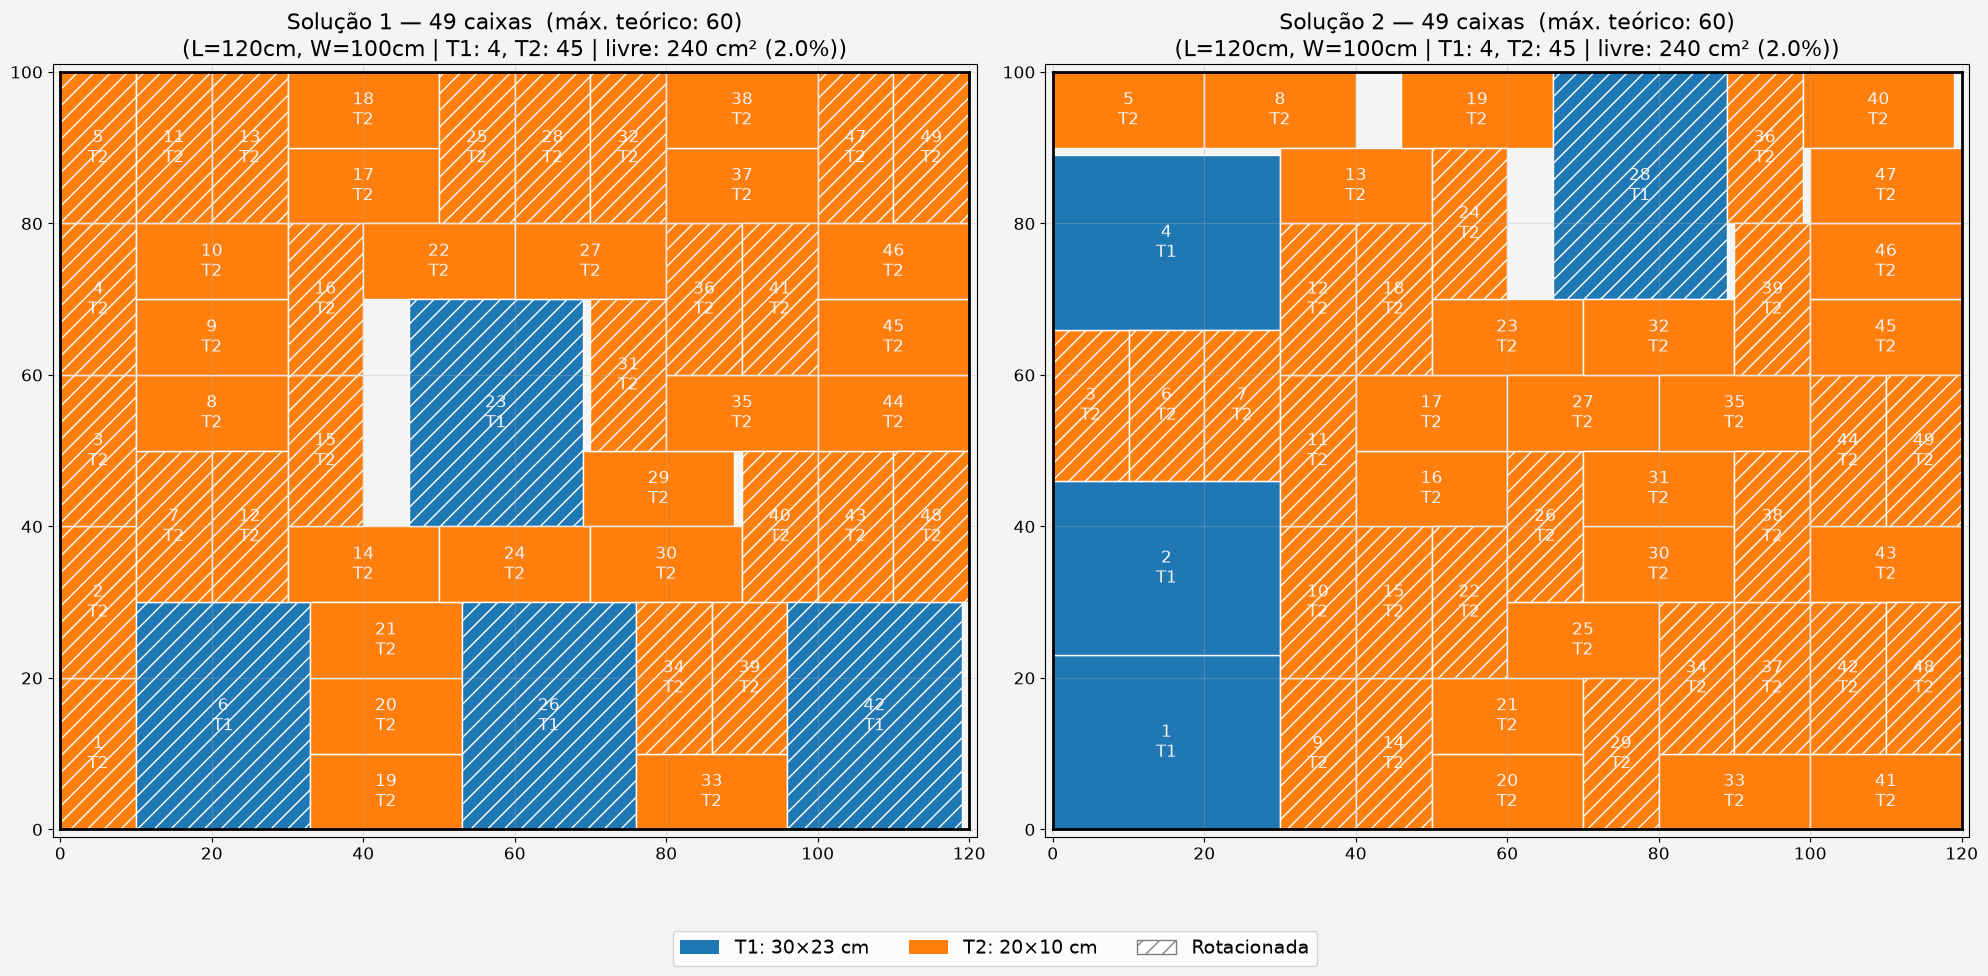

In [ ]:
# Maximixar o numero de caixas
solucoes, qtd_maxima, fig = resolver(comp_palete, larg_palete, caixas, 
                                     qtd_solucoes, tempo_limite, 
                                     objetivo)

In [10]:
objetivo = OBJETIVOS[1]
objetivo

'Minimizar espaço livre no palete'

In [8]:
print(caixas)

[(30, 23, 4), (20, 10, 2)]


Modelo [Minimizar espaço livre no palete]: 2436 variáveis binárias, 877 restrições, 107820 coeficientes não nulos (|H|=35, |V|=25), limite por solução: 10s
Solução 1: 10.1s, encontrada (Optimal)
Solução 2: 10.2s, encontrada (Optimal)


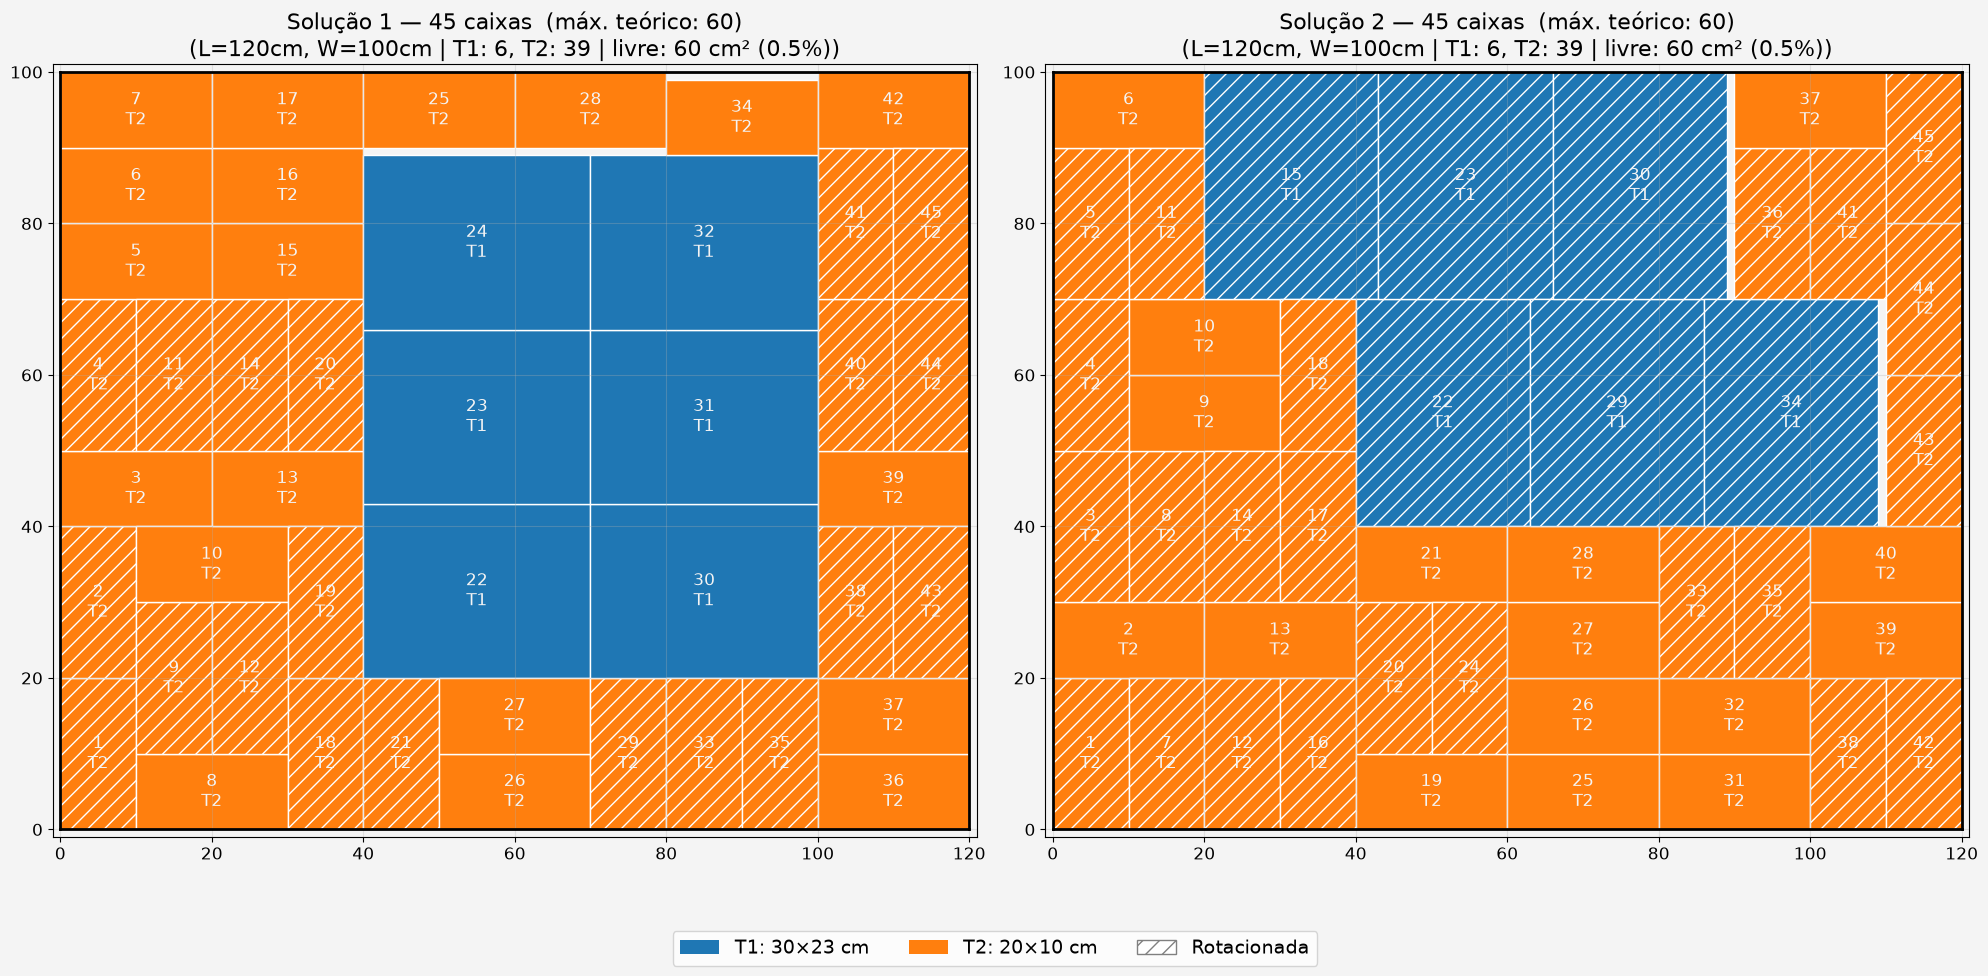

In [11]:
# Maximixar o numero de caixas
solucoes, qtd_maxima, fig = resolver(comp_palete, larg_palete, caixas, 
                                     qtd_solucoes, tempo_limite, 
                                     objetivo)

In [13]:
import os

from dotenv import load_dotenv

load_dotenv("db_palete_caixa.env")

TIPO = os.getenv("ARMAZENAMENTO").strip().lower()

# if TIPO == "s3":
#     NOME = "S3"
# elif TIPO == "local":
#     NOME = "pasta local"
# else:
#     raise ValueError(f"ARMAZENAMENTO inválido: {TIPO!r} (use 'local' ou 's3').")

# print(f"Usando armazenamento: {NOME}")
print(f"Tipo de armazenamento: {TIPO}")

Tipo de armazenamento: local


#### Caminho onde será salvo as soluções

In [14]:
from pathlib import Path

RAIZ_PROJETO = Path('.')
# Caminhos relativos em ARMAZENAMENTO_DIR são resolvidos a partir da raiz do
# projeto (não do diretório de execução), para funcionar em qualquer máquina.
RAIZ = (RAIZ_PROJETO / os.getenv("ARMAZENAMENTO_DIR")).resolve()
print(RAIZ)

/Users/kenjimatoba/cpp/ampp3/palete_caixa/solucoes_salvas


In [15]:
import json
import os
import re
from pathlib import Path


def _nome_seguro(nome: str) -> str:
    """Valida um componente de caminho, impedindo '..', separadores e vazios."""
    if not nome or nome in {".", ".."} or not re.fullmatch(r"[\w\-.@ ]+", nome):
        raise ValueError(f"Nome inválido para armazenamento: {nome!r}")
    return nome


def _pasta(nome_usuario: str, prefixo: str) -> Path:
    return RAIZ / _nome_seguro(nome_usuario) / _nome_seguro(prefixo)


# ─── Escrita ──────────────────────────────────────────────────────────────────

def salvar_solucao(nome_usuario: str, prefixo: str, img_bytes: bytes, meta: dict) -> str:
    """
    Grava a imagem (bytes PNG) e o metadata.json na pasta local.

    Retorno
    -------
    Caminho da pasta da solução (relativo à raiz de armazenamento).
    """
    pasta = _pasta(nome_usuario, prefixo)
    pasta.mkdir(parents=True, exist_ok=True)
    (pasta / "solucoes.png").write_bytes(img_bytes)
    (pasta / "metadata.json").write_text(
        json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    return f"{nome_usuario}/{prefixo}"


# ─── Leitura ──────────────────────────────────────────────────────────────────

def listar_solucoes(nome_usuario: str) -> list:
    """Lista prefixos de soluções de um usuário em ordem decrescente."""
    pasta_usuario = RAIZ / _nome_seguro(nome_usuario)
    if not pasta_usuario.is_dir():
        return []
    return sorted((p.name for p in pasta_usuario.iterdir() if p.is_dir()), reverse=True)

In [ ]:
params = {
    "comprimento_palete_cm": comp_palete,
    "largura_palete_cm":     larg_palete,
    "caixas": [
        {"tipo": t, "comprimento_cm": c, "largura_cm": w, "qtd_minima": q}
        for t, (c, w, q) in enumerate(caixas, start=1)
    ],
    "objetivo": objetivo,
    "qtd_solucoes": int(qtd_solucoes),
    "tempo_limite_s": int(tempo_limite),
}

# Metadados Exemplo
meta = {
    "nome_solucao": nome_solucao.strip(),
    "timestamp": timestamp,
    "parametros": params,
    "qtd_caixas_solucoes": [21, 20],
    "qtd_caixas_por_tipo": [{"T1": 10, "T2": 11}, {"T1": 10, "T2": 10}],
    "area_livre_cm2": [50, 60],
    "posicoes": [
        [{"tipo": t, "orientacao": o, "x": p, "y": q} for t, o, p, q in s]
        for s in solucoes
    ],
    "qtd_caixas_sol1": 21,
    "qtd_caixas_sol2": 20,
}

In [17]:
import io

buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
plt.close(fig)
img_bytes = buf.getvalue()

salvar_solucao(nome_usuario="usuario_exemplo", 
               prefixo=f"{nome_solucao}_{timestamp}", 
               img_bytes=img_bytes, 
               meta=meta)

'usuario_exemplo/solucao_1_20261011_080100'

In [18]:
listar_solucoes(nome_usuario="usuario_exemplo")

['solucao_1_20261011_080100']